Maternal Health Risk Analysis
How does average age, blood pressure, and blood sugar compare across the different risk groups?

Data Source:
This project uses the Maternal Health Risk dataset from the UCI Machine Learning Repository. The data was collected from hospitals, community clinics, and maternal healthcare facilities in rural Bangladesh.

Source: https://archive.ics.uci.edu/dataset/863/maternal+health+risk

License: Creative Commons Attribution 4.0 International (CC BY 4.0)

Variables Used

- Age: Age in years
- SystolicBP: Systolic blood pressure in mmHg
- DiastolicBP: Diastolic blood pressure in mmHg
- BS: Blood sugar in mmol/L
- RiskLevel: Low, mid, or high maternal health risk

The variable definitions and units come from the UCI Maternal Health Risk data dictionary.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

maternal = pd.read_csv("maternal health risk data set.csv")
maternal.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [2]:
print("Shape:", maternal.shape)

print("\nMissing values:")
print(maternal.isnull().sum())

print("\nDuplicate rows:")
print(maternal.duplicated().sum())

Shape: (1014, 7)

Missing values:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

Duplicate rows:
562


The dataset contains 1014 rows and 7 columns. There are no missing values. 
There were 562 duplicate rows identified, but since there is no paitient ID, we cannot determine if they are truly duplicates. They will not be removed as there is no proof there are accidental duplicates. Removing the rows would discard over half the dataset and alter the averages.

In [3]:
group_means = maternal.groupby("RiskLevel")[["Age", "SystolicBP", "DiastolicBP", "BS"]].mean().round(2)
group_means

,Age,SystolicBP,DiastolicBP,BS
RiskLevel,,,,
high risk,36.22,124.19,85.07,12.12
low risk,26.87,105.87,72.53,7.22
mid risk,28.36,113.15,74.23,7.80


Chart Avergae Age by risk level

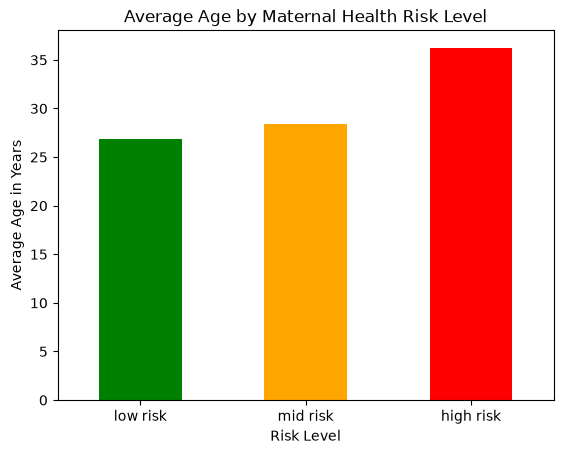

In [4]:
age_means = group_means.loc[["low risk", "mid risk", "high risk"], "Age"]

age_means.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Average Age by Maternal Health Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Age in Years")
plt.xticks(rotation=0)
plt.savefig("average_age_by_risk.png", bbox_inches="tight")
plt.show()

Chart Avergae Age by risk level anaylsis: The highest risk age group is 36.22 years. The mid risk age group is 28.36 years. The lowest risk group age is 26.87 years.

Chart: Average Blood Pressure by Risk Level

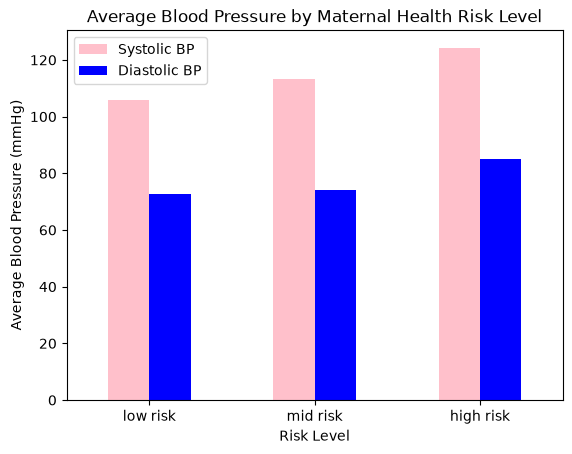

In [5]:
bp_means = group_means.loc[
    ["low risk", "mid risk", "high risk"],
    ["SystolicBP", "DiastolicBP"]]

bp_means.plot(kind="bar", color=["pink", "blue"])
plt.title("Average Blood Pressure by Maternal Health Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Blood Pressure (mmHg)")
plt.xticks(rotation=0)
plt.legend(["Systolic BP", "Diastolic BP"])
plt.savefig("average_blood_pressure_by_risk.png", bbox_inches="tight")
plt.show()

Chart Average Blood Pressure by Risk Level anaylsis: 
Average systolic and diastolic blood pressure increased across the risk groups. 
The high risk group had the highest averages at 124.19 mmHg systolic and 85.07 mmHg diastolic.

Chart Average Blood Pressure by Risk Level

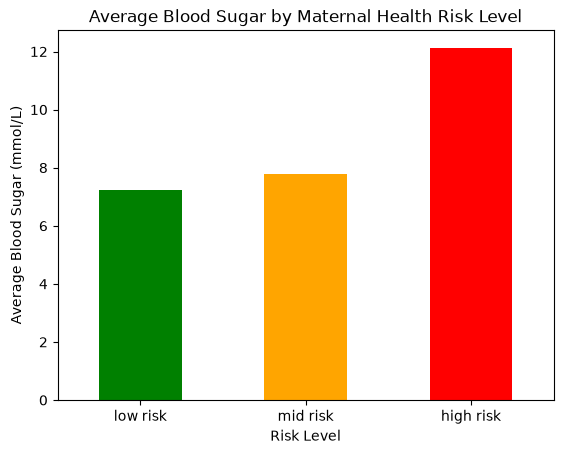

In [6]:
bs_means = group_means.loc[["low risk", "mid risk", "high risk"], "BS"]

bs_means.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Average Blood Sugar by Maternal Health Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Blood Sugar (mmol/L)")
plt.xticks(rotation=0)
plt.savefig("average_blood_sugar_by_risk.png", bbox_inches="tight")
plt.show()

Chart Average Blood Pressure by Risk Level anaylsis:
 The averages were 7.80 mmol/L for the mid-risk group and 7.22 mmol/L for the low-risk group.

In [7]:
maternal["RiskLevel"].value_counts()

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

Conclusion:
The high risk group had the highest average age, systolic blood pressure, diastolic blood pressure, and blood sugar. The average age increased from 26.87 years in the low-risk group to 36.22 years in the high-risk group. Blood pressure increased across the three groups, and the largest difference was seen in blood sugar, which averaged 12.12 mmol/L for the high risk group compared with 7.22 mmol/L for the low risk group. These results show an association between these measurements and risk level, but they do not prove that any one measurement caused the risk classification.